# 60: Event Study Assumption Checks

Before trusting the hypothesis tests in `31_event_study.ipynb`, this notebook checks the
standard event-study assumptions (per https://eventstudy.de/docs/assumptions) against the
already-computed event-study sample:

1. Identifiable event timing
2. Market efficiency (no pre-event anticipation / leakage)
3. Significant impact magnitude
4. Normally distributed estimation-window residuals
5. No autocorrelation in estimation-window residuals
6. Absence of confounding events

This notebook reuses the cached prices and the retained event sample produced by
`31_event_study.ipynb` (Steps 1-3) rather than re-downloading or re-detecting peaks, so
it runs quickly and does not touch any of that notebook's outputs.

## Step 0 — Setup

In [1]:
import pandas as pd
import numpy as np
import warnings
from pathlib import Path
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

OUTPUT_DIR = Path('results/phase_iv')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Same design constants as 31_event_study.ipynb
ESTIMATION_START = -210
ESTIMATION_END   = -11
EVENT_WINDOW     = (-1, 5)
MIN_EST_OBS      = 50
MARKET_TICKER    = 'ACWI'
PRETREND_WINDOW  = (-10, -2)  # untested gap between estimation window end and event window start
RNG_SEED         = 42


/home/le/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Exchange suffix map — copied verbatim from 31_event_study.ipynb (Step 2) so yf_ticker
# can be reconstructed; not stored in the saved event_study_results_v3.parquet.
TICKER_SUFFIX_MAP = {
    # Germany (Frankfurt)
    'SIE':  'SIE.DE',  'BAYN': 'BAYN.DE', 'LHA':  'LHA.DE',
    'BAS':  'BAS.DE',  'ADS':  'ADS.DE',  'VOW3': 'VOW3.DE', 'PAH3': 'PAH3.DE',
    # Switzerland
    'ZURN': 'ZURN.SW', 'NESN': 'NESN.SW', 'NOVN': 'NOVN.SW',
    # UK (London)
    'HSBA': 'HSBA.L',  'LLOY': 'LLOY.L',  'GLEN': 'GLEN.L',
    'RR.':  'RR.L',    'BA.':  'BA.L',     'SVT':  'SVT.L',
    'ULVR': 'ULVR.L',  'UU.':  'UU.L',     'NG.':  'NG.L',
    'AV.':  'AV.L',    'LSEG': 'LSEG.L',   'STAN': 'STAN.L',
    # France (Paris)
    'RNO':  'RNO.PA',  'PUB':  'PUB.PA',   'AC':   'AC.PA',
    'ML':   'ML.PA',   'ALO':  'ALO.PA',   'VIE':  'VIE.PA',
    # Netherlands (Amsterdam)
    'PHIA': 'PHIA.AS', 'UMG':  'UMG.AS',
    # Sweden (Stockholm) — B-share tickers use hyphen on yfinance
    'SAAB B':  'SAAB-B.ST', 'VOLV B':   'VOLV-B.ST', 'ERIC B': 'ERIC-B.ST',
    # Denmark (Copenhagen)
    'PNDORA':  'PNDORA.CO', 'MAERSK B': 'MAERSK-B.CO', 'VWS': 'VWS.CO',
    # Finland
    'NOKIA': 'NOKIA.HE',
    # Spain
    'CLNX':  'CLNX.MC',
    # Belgium
    'ABI':   'ABI.BR',
    # Japan (Tokyo)
    '7203': '7203.T', '8604': '8604.T', '6758': '6758.T',
    '7751': '7751.T', '7733': '7733.T', '7267': '7267.T',
    '7974': '7974.T', '9201': '9201.T', '8306': '8306.T',
    '7201': '7201.T', '9434': '9434.T', '6501': '6501.T',
    '7269': '7269.T', '8316': '8316.T', '2587': '2587.T',
    # Hong Kong
    '823':  '0823.HK',
    # Australia (ASX)
    'MQG': 'MQG.AX', 'QAN': 'QAN.AX', 'WOW': 'WOW.AX', 'WBC': 'WBC.AX',
    # Canada (Toronto)
    'FFH': 'FFH.TO',
    # US — special case (B-share uses hyphen)
    'BRKB': 'BRK-B',
}


In [3]:
PRICE_CACHE = OUTPUT_DIR / 'price_cache_v4_acwi.parquet'
EVENT_STUDY_RESULTS = OUTPUT_DIR / 'event_study_results_v3.parquet'
PEAKS_PATH = Path('results/phase_iii/all_peaks_loose_threshold.parquet')

prices = pd.read_parquet(PRICE_CACHE)
prices.index = pd.to_datetime(prices.index)
returns = np.log(prices / prices.shift(1)).dropna(how='all')

event_df = pd.read_parquet(EVENT_STUDY_RESULTS)
event_df['event_date'] = pd.to_datetime(event_df['event_date'])
event_df['yf_ticker'] = event_df['ticker'].map(TICKER_SUFFIX_MAP).fillna(event_df['ticker'])

all_peaks = pd.read_parquet(PEAKS_PATH)
all_peaks['start_date'] = pd.to_datetime(all_peaks['start_date'])
all_peaks['end_date'] = pd.to_datetime(all_peaks['end_date'])
all_peaks['yf_ticker'] = all_peaks['ticker'].map(TICKER_SUFFIX_MAP).fillna(all_peaks['ticker'])

mkt_rets = returns[MARKET_TICKER].dropna()
trading_cal = mkt_rets.index

print(f'Prices          : {prices.shape}')
print(f'Retained events  : {len(event_df):,} (from {event_df["ticker"].nunique()} firms)')
print(f'Full peak catalog: {len(all_peaks):,}')


Prices          : (4686, 239)
Retained events  : 1,463 (from 210 firms)
Full peak catalog: 1,774


## Step 1 — Helper functions

The saved `event_study_results_v3.parquet` carries the fitted `alpha`/`beta`/`resid_std` for
each event, but not the per-day residual *series* from the estimation window, which several
of the checks below need (Shapiro-Wilk, Durbin-Watson, Ljung-Box). This refits the market
model for every retained event using the cached return data — no network calls, since prices
are already local — and keeps the residual series alongside each event.

In [4]:
def get_trading_day_offset(date_index, ref_date, offset):
    pos = date_index.get_indexer([ref_date], method='ffill')[0]
    if pos < 0:
        return None
    target = pos + offset
    if target < 0 or target >= len(date_index):
        return None
    return date_index[target]


def estimate_market_model_with_resid(firm_rets, market_rets, est_start, est_end):
    mask = (firm_rets.index >= est_start) & (firm_rets.index <= est_end)
    y = firm_rets.loc[mask].dropna()
    x = market_rets.reindex(y.index).dropna()
    y, x = y.align(x, join='inner')
    if len(y) < MIN_EST_OBS:
        return None
    slope, intercept, *_ = stats.linregress(x, y)
    resid = y - (intercept + slope * x)
    return intercept, slope, resid


In [5]:
print('Refitting market model with residual series for each retained event...')

residual_series = {}   # peak_id -> estimation-window residual Series (datetime-indexed)
refit_params = {}       # peak_id -> (alpha, beta)

for _, ev in tqdm(event_df.iterrows(), total=len(event_df), desc='Refitting'):
    yf_tick = ev['yf_ticker']
    if yf_tick not in returns.columns:
        continue
    firm_rets = returns[yf_tick].dropna()
    ref_date = ev['event_date']

    est_s = get_trading_day_offset(trading_cal, ref_date, ESTIMATION_START)
    est_e = get_trading_day_offset(trading_cal, ref_date, ESTIMATION_END)
    if est_s is None or est_e is None:
        continue

    model = estimate_market_model_with_resid(firm_rets, mkt_rets, est_s, est_e)
    if model is None:
        continue
    alpha, beta, resid = model
    residual_series[ev['peak_id']] = resid
    refit_params[ev['peak_id']] = (alpha, beta)

print(f'Residual series recovered for {len(residual_series):,} / {len(event_df):,} events')


Refitting market model with residual series for each retained event...


Refitting: 100%|██████████| 1463/1463 [00:02<00:00, 654.48it/s]

Residual series recovered for 1,463 / 1,463 events


## Step 2 — Assumption 1: Identifiable Event Timing

An event study needs "a clear date or narrow time frame" for each event. Our peaks are
detected as multi-day spans (`duration_days`), so a long span makes `start_date` a fuzzier
proxy for the true market-moving date — abnormal returns can bleed across the [−1,+5]
window boundary.

EVENT DURATION (identifiability of the event date)
count    1463.000000
mean        2.641148
std         1.027196
min         2.000000
25%         2.000000
50%         2.000000
75%         3.000000
max        10.000000
  2-day peaks (narrowest)        : 897 (61.3%)
  duration_days > 2 (fuzzier date): 566 (38.7%)
  duration_days > 5 (very fuzzy)  : 35 (2.4%)


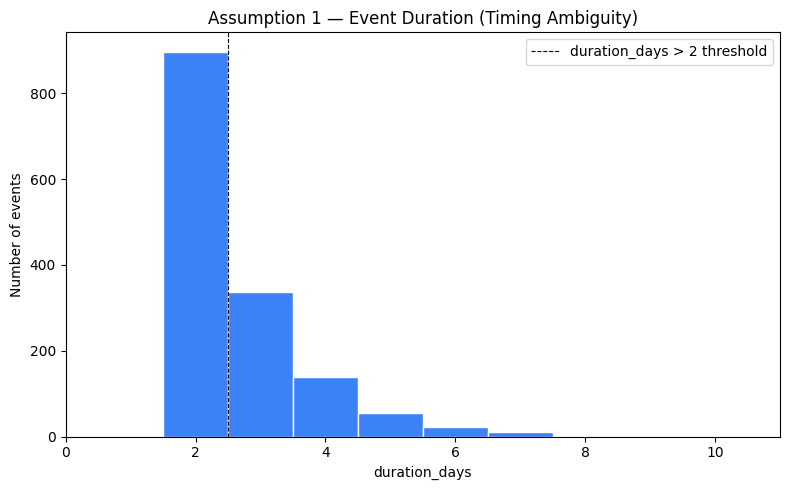

In [6]:
dur = event_df['duration_days']

print('EVENT DURATION (identifiability of the event date)')
print(dur.describe().to_string())
print(f'  2-day peaks (narrowest)        : {(dur == 2).sum():,} ({(dur == 2).mean()*100:.1f}%)')
print(f'  duration_days > 2 (fuzzier date): {(dur > 2).sum():,} ({(dur > 2).mean()*100:.1f}%)')
print(f'  duration_days > 5 (very fuzzy)  : {(dur > 5).sum():,} ({(dur > 5).mean()*100:.1f}%)')

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(dur, bins=range(1, int(dur.max()) + 2), color='#3b82f6', edgecolor='white', align='left')
ax.axvline(2.5, color='black', lw=0.8, ls='--', label='duration_days > 2 threshold')
ax.set_xlabel('duration_days')
ax.set_ylabel('Number of events')
ax.set_title('Assumption 1 — Event Duration (Timing Ambiguity)')
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'assump1_event_duration.png', dpi=150, bbox_inches='tight')
plt.show()

pct_fuzzy_timing = (dur > 2).mean() * 100


## Step 3 — Assumption 2: Market Efficiency (Pre-Trend / Anticipation Test)

Under semi-strong market efficiency, abnormal returns should not systematically appear
*before* the event is publicly known. We test the untested gap between the end of the
estimation window (day −11) and the start of the event window (day −1): trading days
[−10, −2]. A significant non-zero mean abnormal return there suggests information leakage
or a misdated peak — exactly the failure mode `duration_days` flags above.

PRE-TREND TEST, trading days [-10,-2] (gap between estimation window and event window)
  N events               : 1,463
  Mean pre-trend CAR     : -0.037%
  Two-sided t-test H0=0  : t=-0.243, p=0.8080
  % events individually flagged (|pre-trend CAR| > 1.96*SE) : 6.4%


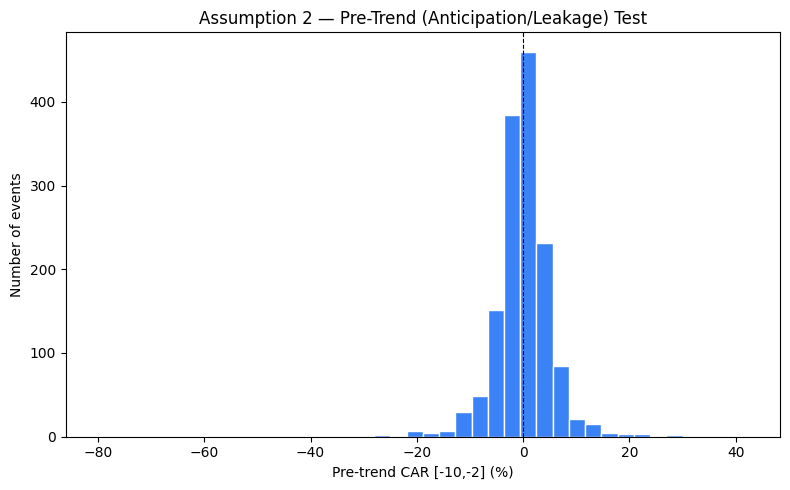

In [7]:
pretrend_cars = []

for _, ev in event_df.iterrows():
    peak_id = ev['peak_id']
    if peak_id not in refit_params:
        continue
    alpha, beta = refit_params[peak_id]
    yf_tick = ev['yf_ticker']
    firm_rets = returns[yf_tick].dropna()
    ref_date = ev['event_date']

    pre_s = get_trading_day_offset(trading_cal, ref_date, PRETREND_WINDOW[0])
    pre_e = get_trading_day_offset(trading_cal, ref_date, PRETREND_WINDOW[1])
    if pre_s is None or pre_e is None:
        continue

    pre_days = trading_cal[(trading_cal >= pre_s) & (trading_cal <= pre_e)]
    ar_pre = (firm_rets.reindex(pre_days) - (alpha + beta * mkt_rets.reindex(pre_days))).dropna()
    if ar_pre.empty:
        continue

    pretrend_cars.append({
        'peak_id': peak_id,
        'pretrend_car': ar_pre.sum(),
        'resid_std': ev['resid_std'],
        'n_pre_days': len(ar_pre),
    })

pretrend_df = pd.DataFrame(pretrend_cars)
pretrend_df['flag_pretrend'] = pretrend_df['pretrend_car'].abs() > 1.96 * pretrend_df['resid_std'] * np.sqrt(pretrend_df['n_pre_days'])

t_pre, p_pre = stats.ttest_1samp(pretrend_df['pretrend_car'], 0)
pct_flagged_pretrend = pretrend_df['flag_pretrend'].mean() * 100

print('PRE-TREND TEST, trading days [-10,-2] (gap between estimation window and event window)')
print(f'  N events               : {len(pretrend_df):,}')
print(f'  Mean pre-trend CAR     : {pretrend_df["pretrend_car"].mean()*100:+.3f}%')
print(f'  Two-sided t-test H0=0  : t={t_pre:+.3f}, p={p_pre:.4f}')
print(f'  % events individually flagged (|pre-trend CAR| > 1.96*SE) : {pct_flagged_pretrend:.1f}%')

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(pretrend_df['pretrend_car'] * 100, bins=40, color='#3b82f6', edgecolor='white')
ax.axvline(0, color='black', lw=0.8, ls='--')
ax.set_xlabel('Pre-trend CAR [-10,-2] (%)')
ax.set_ylabel('Number of events')
ax.set_title('Assumption 2 — Pre-Trend (Anticipation/Leakage) Test')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'assump2_pretrend.png', dpi=150, bbox_inches='tight')
plt.show()


## Step 4 — Assumption 3: Significant Impact Magnitude

Effects need to be large enough to detect above the normal noise in returns. This reports
the cross-sectional distribution of each event's day-0 abnormal return and CAR, standardized
by its own estimation-window residual std (`resid_std`), as a measure of per-event effect
size — the same standardization used in `scar` in `31_event_study.ipynb`.

STANDARDIZED EFFECT SIZE DISTRIBUTION

Standardized day-0 AR (ar_day_0 / resid_std):
count    1463.000000
mean       -0.024241
std         1.203473
min       -11.183594
25%        -0.567393
50%        -0.027693
75%         0.512277
max        11.896095

Standardized CAR (scar):
count    1463.000000
mean       -0.119378
std         1.224455
min       -12.740267
25%        -0.696614
50%        -0.051811
75%         0.532960
max         6.880709

Mean |scar|              : 0.833
Share with |scar| > 1.0  : 28.0%
Share with |scar| > 1.96 : 7.7%
(A mean |scar| well below ~1 indicates the per-event effect is small relative to firm-
 specific noise, so detecting it relies on pooling many events cross-sectionally —
 which is exactly why Step 4 of 31_event_study.ipynb uses BMP/Wilcoxon across the full
 sample rather than relying on any single event.)


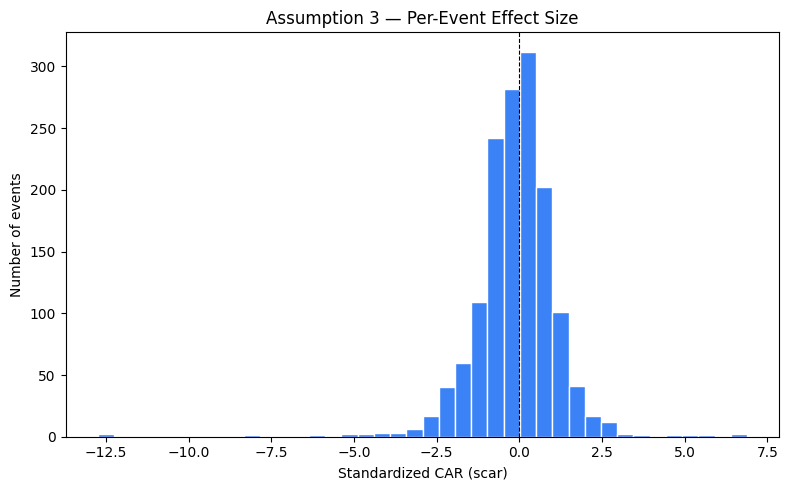

In [8]:
std_ar0 = event_df['ar_day_0'] / event_df['resid_std']
std_car = event_df['scar']  # already resid-std-standardized CAR, computed in 31_event_study.ipynb

print('STANDARDIZED EFFECT SIZE DISTRIBUTION')
print('\nStandardized day-0 AR (ar_day_0 / resid_std):')
print(std_ar0.describe().to_string())

print('\nStandardized CAR (scar):')
print(std_car.describe().to_string())

mean_abs_scar = std_car.abs().mean()
print(f'\nMean |scar|              : {mean_abs_scar:.3f}')
print(f'Share with |scar| > 1.0  : {(std_car.abs() > 1.0).mean()*100:.1f}%')
print(f'Share with |scar| > 1.96 : {(std_car.abs() > 1.96).mean()*100:.1f}%')
print('(A mean |scar| well below ~1 indicates the per-event effect is small relative to firm-')
print(' specific noise, so detecting it relies on pooling many events cross-sectionally —')
print(' which is exactly why Step 4 of 31_event_study.ipynb uses BMP/Wilcoxon across the full')
print(' sample rather than relying on any single event.)')

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(std_car.dropna(), bins=40, color='#3b82f6', edgecolor='white')
ax.axvline(0, color='black', lw=0.8, ls='--')
ax.set_xlabel('Standardized CAR (scar)')
ax.set_ylabel('Number of events')
ax.set_title('Assumption 3 — Per-Event Effect Size')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'assump3_effect_size.png', dpi=150, bbox_inches='tight')
plt.show()


## Step 5 — Assumption 4: Normally Distributed Residuals

Parametric tests (the plain t-test) assume the market-model residuals used to compute
abnormal returns are normally distributed. Shapiro-Wilk is run per-event on its own
200-day estimation-window residual series; non-normal residuals motivate preferring the
BMP test and Wilcoxon signed-rank test already used downstream, over a naive t-test.

SHAPIRO-WILK TEST ON ESTIMATION-WINDOW RESIDUALS (per event)
  N events tested                 : 1,463
  % rejecting normality (p<0.05)  : 86.9%
count    1.463000e+03
mean     4.378889e-02
std      1.420336e-01
min      1.163587e-24
25%      2.025911e-10
50%      2.500741e-06
75%      2.888089e-03
max      9.950062e-01


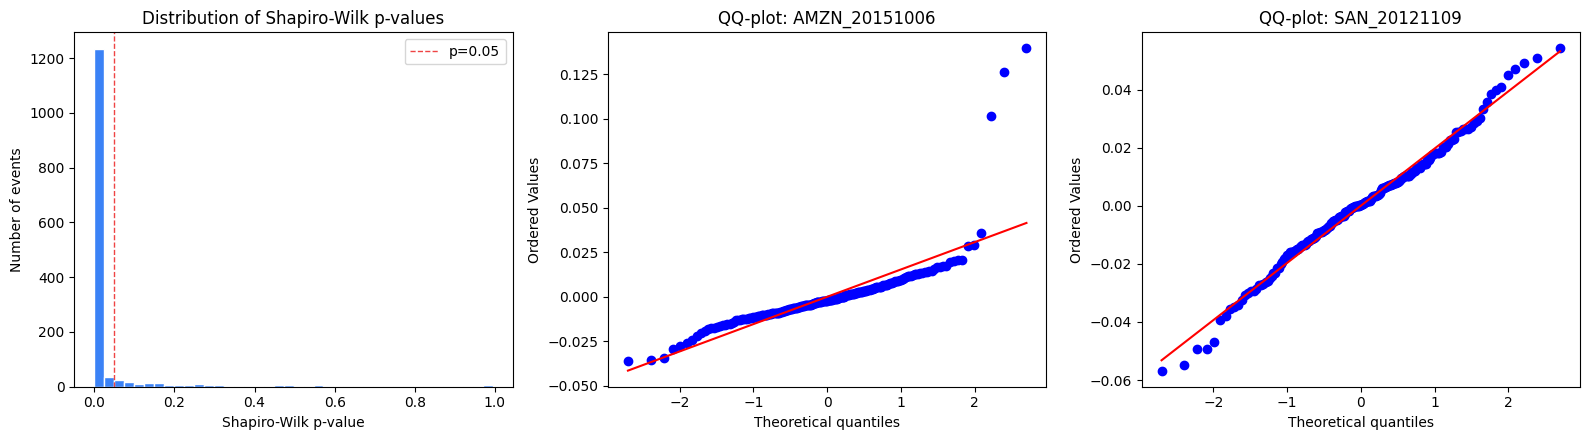

In [9]:
shapiro_rows = []
for peak_id, resid in residual_series.items():
    if len(resid) < 3:
        continue
    stat, p = stats.shapiro(resid.values)
    shapiro_rows.append({'peak_id': peak_id, 'shapiro_stat': stat, 'shapiro_p': p})

shapiro_df = pd.DataFrame(shapiro_rows)
pct_reject_normality = (shapiro_df['shapiro_p'] < 0.05).mean() * 100

print('SHAPIRO-WILK TEST ON ESTIMATION-WINDOW RESIDUALS (per event)')
print(f'  N events tested                 : {len(shapiro_df):,}')
print(f'  % rejecting normality (p<0.05)  : {pct_reject_normality:.1f}%')
print(shapiro_df['shapiro_p'].describe().to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(shapiro_df['shapiro_p'], bins=40, color='#3b82f6', edgecolor='white')
axes[0].axvline(0.05, color='#ef4444', lw=1, ls='--', label='p=0.05')
axes[0].set_xlabel('Shapiro-Wilk p-value')
axes[0].set_ylabel('Number of events')
axes[0].set_title('Distribution of Shapiro-Wilk p-values')
axes[0].legend()

# Representative QQ-plots for a fixed random sample of events
rng = np.random.default_rng(RNG_SEED)
sample_ids = rng.choice(list(residual_series.keys()), size=2, replace=False)
for ax, peak_id in zip(axes[1:], sample_ids):
    stats.probplot(residual_series[peak_id].values, dist='norm', plot=ax)
    ax.set_title(f'QQ-plot: {peak_id}')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'assump4_normality.png', dpi=150, bbox_inches='tight')
plt.show()


## Step 6 — Assumption 5: No Autocorrelation

Returns (and hence market-model residuals) should be independent across time; serial
correlation inflates t-statistics and overstates significance. Durbin-Watson (expect ~2
under no autocorrelation) and Ljung-Box (lag=5) are computed on each event's
estimation-window residual series.

AUTOCORRELATION DIAGNOSTICS ON ESTIMATION-WINDOW RESIDUALS (per event)
  N events tested                          : 1,463

Durbin-Watson distribution (2.0 = no autocorrelation):
count    1463.000000
mean        2.004132
std         0.183784
min         1.257818
25%         1.889028
50%         2.003912
75%         2.115200
max         2.703411

  % events with significant Ljung-Box (lag=5, p<0.05) : 12.6%


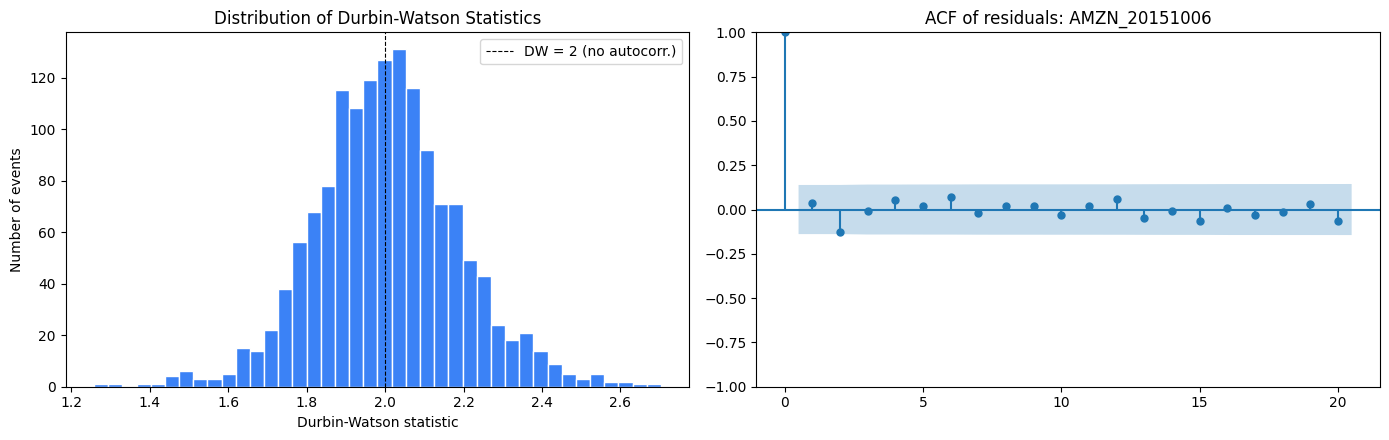

In [10]:
autocorr_rows = []
for peak_id, resid in residual_series.items():
    if len(resid) < 10:
        continue
    dw = durbin_watson(resid.values)
    lb = acorr_ljungbox(resid.values, lags=[5], return_df=True)
    lb_p = lb['lb_pvalue'].iloc[0]
    autocorr_rows.append({'peak_id': peak_id, 'durbin_watson': dw, 'ljungbox_p': lb_p})

autocorr_df = pd.DataFrame(autocorr_rows)
pct_sig_autocorr = (autocorr_df['ljungbox_p'] < 0.05).mean() * 100

print('AUTOCORRELATION DIAGNOSTICS ON ESTIMATION-WINDOW RESIDUALS (per event)')
print(f'  N events tested                          : {len(autocorr_df):,}')
print('\nDurbin-Watson distribution (2.0 = no autocorrelation):')
print(autocorr_df['durbin_watson'].describe().to_string())
print(f'\n  % events with significant Ljung-Box (lag=5, p<0.05) : {pct_sig_autocorr:.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(autocorr_df['durbin_watson'], bins=40, color='#3b82f6', edgecolor='white')
axes[0].axvline(2.0, color='black', lw=0.8, ls='--', label='DW = 2 (no autocorr.)')
axes[0].set_xlabel('Durbin-Watson statistic')
axes[0].set_ylabel('Number of events')
axes[0].set_title('Distribution of Durbin-Watson Statistics')
axes[0].legend()

# Representative ACF plot for one event, fixed by seed for reproducibility
rng = np.random.default_rng(RNG_SEED)
sample_id = rng.choice(list(residual_series.keys()))
plot_acf(residual_series[sample_id].values, lags=20, ax=axes[1])
axes[1].set_title(f'ACF of residuals: {sample_id}')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'assump5_autocorrelation.png', dpi=150, bbox_inches='tight')
plt.show()


## Step 7 — Assumption 6: Absence of Confounding Events

The event window should not overlap an unrelated event for the same firm. We don't have an
earnings/dividend calendar, so this checks a narrower but directly available condition:
whether a retained event's [−1,+5] window overlaps *another* detected reputational-risk
peak for the same firm in the full peak catalog (not just the retained sample). This is a
same-pipeline-only confounding check, not a full screen against market-wide corporate
actions.

In [11]:
peaks_by_ticker = {tkr: grp for tkr, grp in all_peaks.groupby('yf_ticker')}

confound_flags = []
for _, ev in event_df.iterrows():
    yf_tick = ev['yf_ticker']
    ref_date = ev['event_date']
    peak_id = ev['peak_id']

    evt_s = get_trading_day_offset(trading_cal, ref_date, EVENT_WINDOW[0])
    evt_e = get_trading_day_offset(trading_cal, ref_date, EVENT_WINDOW[1])
    if evt_s is None or evt_e is None:
        continue

    other_peaks = peaks_by_ticker.get(yf_tick)
    is_confounded = False
    if other_peaks is not None:
        others = other_peaks[other_peaks['peak_id'] != peak_id]
        overlap = (others['start_date'] <= evt_e) & (others['end_date'] >= evt_s)
        is_confounded = bool(overlap.any())

    confound_flags.append({'peak_id': peak_id, 'confounded': is_confounded})

confound_df = pd.DataFrame(confound_flags)
pct_confounded = confound_df['confounded'].mean() * 100

print('CONFOUNDING-EVENT CHECK (same-firm overlapping peaks only)')
print(f'  N events checked                : {len(confound_df):,}')
print(f'  Flagged as confounded           : {confound_df["confounded"].sum():,} ({pct_confounded:.1f}%)')
print('\n  Note: no earnings/dividend/corporate-action calendar is available, so this check')
print('  only catches overlap with OTHER detected reputational-risk peaks for the same firm,')
print('  not unrelated market-wide confounders.')


CONFOUNDING-EVENT CHECK (same-firm overlapping peaks only)
  N events checked                : 1,463
  Flagged as confounded           : 17 (1.2%)

  Note: no earnings/dividend/corporate-action calendar is available, so this check
  only catches overlap with OTHER detected reputational-risk peaks for the same firm,
  not unrelated market-wide confounders.


## Step 8 — Summary Table

One row per assumption with its headline diagnostic, saved for reference alongside the
main event-study outputs in `31_event_study.ipynb`.

In [12]:
assumption_summary = pd.DataFrame([
    dict(assumption='1. Identifiable event timing',
         metric='% events with duration_days > 2',
         value=f'{pct_fuzzy_timing:.1f}%',
         n=len(event_df)),
    dict(assumption='2. Market efficiency (pre-trend)',
         metric=f'Pre-trend t-test p-value (H0: mean CAR[-10,-2]=0)',
         value=f'{p_pre:.4f}',
         n=len(pretrend_df)),
    dict(assumption='3. Significant impact magnitude',
         metric='Mean |scar| (standardized CAR)',
         value=f'{mean_abs_scar:.3f}',
         n=event_df['scar'].notna().sum()),
    dict(assumption='4. Normally distributed residuals',
         metric='% events rejecting normality (Shapiro-Wilk p<0.05)',
         value=f'{pct_reject_normality:.1f}%',
         n=len(shapiro_df)),
    dict(assumption='5. No autocorrelation',
         metric='% events with significant Ljung-Box (lag=5, p<0.05)',
         value=f'{pct_sig_autocorr:.1f}%',
         n=len(autocorr_df)),
    dict(assumption='6. No confounding events',
         metric='% events flagged as confounded (same-firm overlap)',
         value=f'{pct_confounded:.1f}%',
         n=len(confound_df)),
])

print('='*78)
print('EVENT STUDY ASSUMPTION CHECKS — SUMMARY')
print('='*78)
print(assumption_summary.to_string(index=False))

assumption_summary.to_csv(OUTPUT_DIR / 'assumption_checks_summary.csv', index=False)
print('\n✓ Summary saved to assumption_checks_summary.csv')
print('\nNext: proceed to 31_event_study.ipynb for the main hypothesis tests, interpreting')
print('them in light of any assumption violations flagged above.')


EVENT STUDY ASSUMPTION CHECKS — SUMMARY
                       assumption                                              metric  value    n
     1. Identifiable event timing                     % events with duration_days > 2  38.7% 1463
 2. Market efficiency (pre-trend)   Pre-trend t-test p-value (H0: mean CAR[-10,-2]=0) 0.8080 1463
  3. Significant impact magnitude                      Mean |scar| (standardized CAR)  0.833 1463
4. Normally distributed residuals  % events rejecting normality (Shapiro-Wilk p<0.05)  86.9% 1463
            5. No autocorrelation % events with significant Ljung-Box (lag=5, p<0.05)  12.6% 1463
         6. No confounding events  % events flagged as confounded (same-firm overlap)   1.2% 1463

✓ Summary saved to assumption_checks_summary.csv

Next: proceed to 31_event_study.ipynb for the main hypothesis tests, interpreting
them in light of any assumption violations flagged above.
